# Task 2 — Kiểm tra viền và màu

ConvNeXt-Tiny và MobileNetV3-Large, **Phase 1 main, seed 42**, cùng **532 ảnh test/17 loài**. Mặc định dùng checkpoint `best` được dùng trong paper; chọn `last` trong cell cấu hình nếu muốn kiểm tra thêm checkpoint cuối.

Chạy **Run All** sau khi kiểm tra `CHECKPOINT_ROOT`. Notebook không retrain và không dùng checkpoint CV trên tập test Phase 1, vì các fold CV có thể đã train trên những ảnh này. Kết quả mới lưu trong `runs/<timestamp>-<id>/`; các CSV cũ được giữ làm lịch sử, không đại diện cho lần chạy này.

In [1]:
from pathlib import Path
import sys

if Path('/content').exists():
    ROOT = Path('/content/woodbench')
else:
    ROOT = Path.cwd()
    candidates = [ROOT, *ROOT.parents, ROOT / 'woodbench']
    ROOT = next((p for p in candidates if (p / 'src/data/transforms.py').is_file()), ROOT)

assert (ROOT / 'src/data/transforms.py').is_file(), f'Không tìm thấy repo woodbench: {ROOT}'
sys.path.insert(0, str(ROOT))
FEEDBACK = ROOT / 'notebooks/phase 2/supervisor-feedback'
sys.path.insert(0, str(FEEDBACK))
print(f'ROOT: {ROOT}')


ROOT: /home/sakana/Code/ManifoldsTeam/woodbench


## Cấu hình và checkpoint

Đường dẫn theo repo ROOT, dùng được ở local/Colab. GPU được dùng nếu có; CPU cũng chạy được. Registry nguồn cung cấp ID và cấu hình training của hai run.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from IPython.display import display
from inference_checks import ROBUSTNESS, make_transform, evaluate_models

# Chỉ inference: hai model chạy lần lượt, không có training.
MODELS = ['convnext_tiny', 'mobilenetv3_large']
SEED = 42
CHECKPOINT_KIND = 'best'  # checkpoint trong paper; đổi thành 'last' để kiểm tra checkpoint cuối
CHECKPOINT_ROOT = ROOT / 'data/experiments/Task-B-new/19-08-2026/main/seed_42'
TEST_DIR = ROOT / 'data/task-B-group-split/test'
SOURCE_DIR = ROOT / 'docs/reports/experiments/phase_1b/final_b_new_recomputed/20260819T043733Z'
SOURCE_REGISTRY = SOURCE_DIR / 'task-b-17class-20260819T043733Z-registry.csv'
OUTPUT_PARENT = ROOT / 'artifacts/phase_2/supervisor-feedback/task_02_robustness_tests/runs'
CONDITIONS = ROBUSTNESS
BATCH_SIZE = 32  # batch inference, không thay đổi batch training
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

assert CHECKPOINT_KIND in ('last', 'best')
source = pd.read_csv(SOURCE_REGISTRY, dtype=str).fillna('')
run_rows = source[
    source['run_id'].str.startswith('taskB17__main__')
    & source['seed'].eq(str(SEED)) & source['backbone'].isin(MODELS)
].to_dict('records')
assert len(run_rows) == len(MODELS) and {r['backbone'] for r in run_rows} == set(MODELS)
CLASS_NAMES = json.loads((SOURCE_DIR / 'metadata.json').read_text())['classes']
checkpoint_paths = {
    r['run_id']: CHECKPOINT_ROOT / r['backbone'] / f"{r['backbone']}_seed{SEED}_{CHECKPOINT_KIND}.pth"
    for r in run_rows
}
for r in run_rows:
    path = checkpoint_paths[r['run_id']]
    assert path.is_file(), f'Thiếu checkpoint: {path}; cập nhật CHECKPOINT_ROOT trong cell này'
    print(r['backbone'], '->', path.relative_to(ROOT))
print('Device:', DEVICE, '| Test:', TEST_DIR, '| Probes:', CONDITIONS)


convnext_tiny -> data/experiments/Task-B-new/19-08-2026/main/seed_42/convnext_tiny/convnext_tiny_seed42_best.pth
mobilenetv3_large -> data/experiments/Task-B-new/19-08-2026/main/seed_42/mobilenetv3_large/mobilenetv3_large_seed42_best.pth
Device: cuda | Test: /home/sakana/Code/ManifoldsTeam/woodbench/data/task-B-group-split/test | Probes: ('baseline', 'center_crop_70', 'edge_mask_15', 'grayscale')


## Xem trước phép kiểm tra

Ảnh gốc; center-crop 70% theo mỗi chiều rồi resize lại; che 15% mỗi viền bằng màu đen; grayscale giữ 3 kênh RGB.

Tất cả nhánh đều bắt đầu bằng **Resize(224×224)**, sau đó mới can thiệp ảnh, cuối cùng ToTensor và ImageNet normalize. Không random augmentation. Hình minh họa dùng chính transform được chạy khi inference.

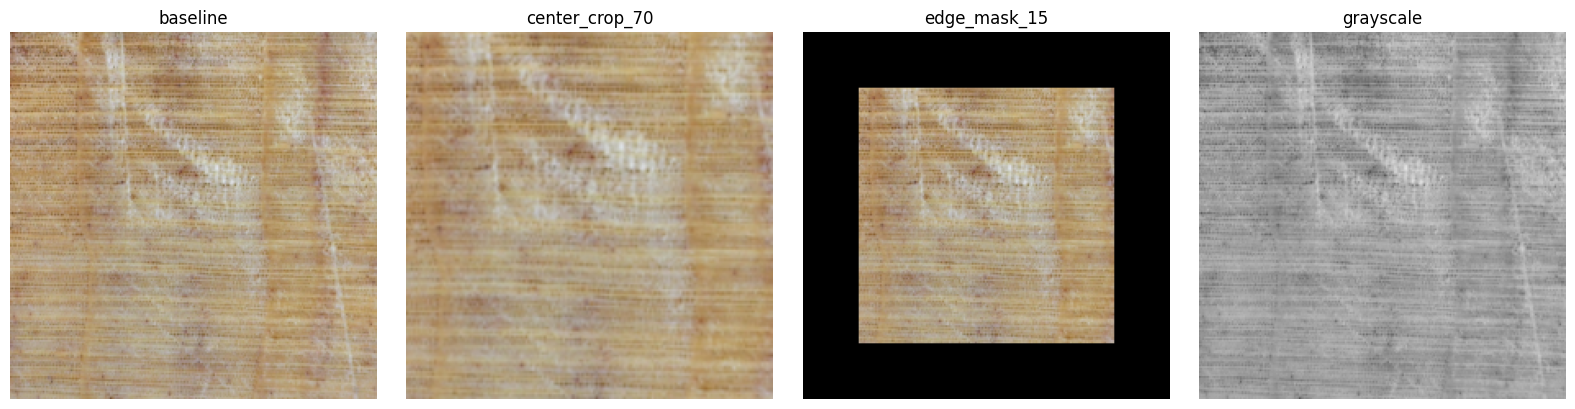

In [3]:
sample_path = next(TEST_DIR.glob('*/*.png'))
with Image.open(sample_path) as image:
    sample = image.convert('RGB')
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(16, 4))
for ax, condition in zip(axes, CONDITIONS):
    tensor = make_transform(condition)(sample)
    pixels = tensor.permute(1, 2, 0).numpy()
    pixels = pixels * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    ax.imshow(np.clip(pixels, 0, 1))
    ax.set_title(condition)
    ax.axis('off')
plt.tight_layout()
plt.show()


## Chạy inference và lưu kết quả

Dùng `eval()` và `inference_mode()`, FP32, không autocast; hai model chạy lần lượt để tiết kiệm VRAM. Mỗi phép kiểm tra dùng cùng ảnh và cùng nhãn. Accuracy và macro-F1 được tính trên toàn bộ 17 lớp.

In [4]:
results_df, OUTPUT_DIR = evaluate_models(
    root=ROOT, run_rows=run_rows, checkpoint_paths=checkpoint_paths,
    test_dir=TEST_DIR, conditions=CONDITIONS, output_parent=OUTPUT_PARENT,
    notebook='notebooks/phase 2/supervisor-feedback/task_02_robustness_tests/robustness_tests.ipynb',
    class_names=CLASS_NAMES, device=DEVICE, batch_size=BATCH_SIZE,
    source_registry=SOURCE_REGISTRY.relative_to(ROOT).as_posix(),
)
print('Kết quả mới:', OUTPUT_DIR.relative_to(ROOT))
print('Mỗi lần chạy có results.csv, registry riêng, predictions/ và metadata.json.')


convnext_tiny: baseline:   0%|          | 0/17 [00:00<?, ?it/s]

convnext_tiny | baseline: accuracy 99.81%, macro-F1 99.83%


convnext_tiny: center_crop_70:   0%|          | 0/17 [00:00<?, ?it/s]

convnext_tiny | center_crop_70: accuracy 96.62%, macro-F1 96.69%


convnext_tiny: edge_mask_15:   0%|          | 0/17 [00:00<?, ?it/s]

convnext_tiny | edge_mask_15: accuracy 99.44%, macro-F1 99.46%


... (6 outputs left out)

mobilenetv3_large: edge_mask_15:   0%|          | 0/17 [00:00<?, ?it/s]

mobilenetv3_large | edge_mask_15: accuracy 88.16%, macro-F1 87.88%


mobilenetv3_large: grayscale:   0%|          | 0/17 [00:00<?, ?it/s]

mobilenetv3_large | grayscale: accuracy 47.18%, macro-F1 44.25%
Kết quả mới: notebooks/phase 2/supervisor-feedback/task_02_robustness_tests/runs/inference-20261003T163224Z-1fde2140
Mỗi lần chạy có results.csv, registry riêng, predictions/ và metadata.json.


## So sánh kết quả

`drop_pp` = accuracy baseline của **chính model đó** trừ accuracy sau can thiệp, tính bằng điểm phần trăm. Registry chỉ có một dòng cho mỗi training run; các phép kiểm tra và dự đoán đều liên kết bằng `run_id`. Không so mức giảm của MobileNet với baseline ConvNeXt.

,backbone,test,accuracy,macro_f1,drop_pp,run_id
0,convnext_tiny,baseline,99.81,99.83,0.00,taskB17__main__seed_42__convnext_tiny
1,convnext_tiny,center_crop_70,96.62,96.69,3.20,taskB17__main__seed_42__convnext_tiny
2,convnext_tiny,edge_mask_15,99.44,99.46,0.38,taskB17__main__seed_42__convnext_tiny
3,convnext_tiny,grayscale,73.68,70.33,26.13,taskB17__main__seed_42__convnext_tiny
4,mobilenetv3_large,baseline,98.68,98.79,0.00,taskB17__main__seed_42__mobilenetv3_large
5,mobilenetv3_large,center_crop_70,91.54,91.71,7.14,taskB17__main__seed_42__mobilenetv3_large
6,mobilenetv3_large,edge_mask_15,88.16,87.88,10.53,taskB17__main__seed_42__mobilenetv3_large
7,mobilenetv3_large,grayscale,47.18,44.25,51.50,taskB17__main__seed_42__mobilenetv3_large


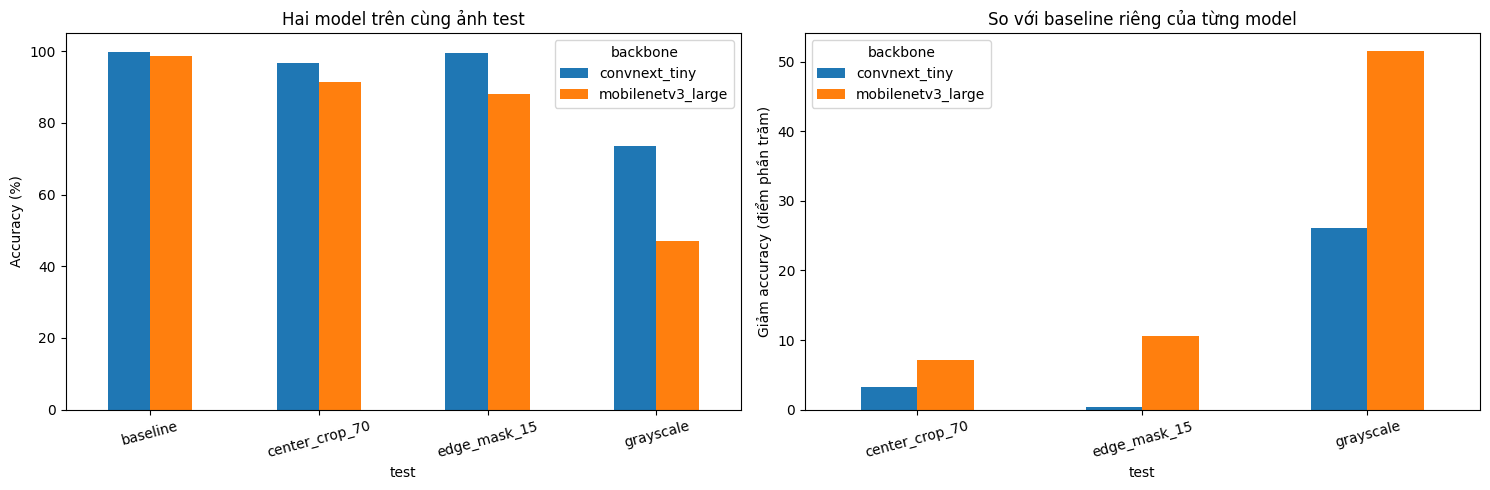

In [5]:
table = results_df[['backbone', 'test', 'accuracy', 'macro_f1', 'drop_pp', 'run_id']].copy()
table['accuracy'] *= 100
table['macro_f1'] *= 100
display(table.round({'accuracy': 2, 'macro_f1': 2, 'drop_pp': 2}))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
accuracy = results_df.pivot(index='test', columns='backbone', values='accuracy').reindex(CONDITIONS) * 100
drops = results_df.pivot(index='test', columns='backbone', values='drop_pp').reindex(CONDITIONS[1:])
accuracy.plot.bar(ax=axes[0], ylabel='Accuracy (%)', ylim=(0, 105), rot=15)
drops.plot.bar(ax=axes[1], ylabel='Giảm accuracy (điểm phần trăm)', rot=15)
axes[0].set_title('Hai model trên cùng ảnh test')
axes[1].set_title('So với baseline riêng của từng model')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'comparison.png', dpi=150)
plt.show()


Mức giảm cho biết model nhạy với phép can thiệp đã thử; chưa đủ để khẳng định model chỉ dùng màu/viền hoặc đã học đúng đặc điểm giải phẫu. Dùng `results.csv` và `metadata.json` của **lần chạy mới** để cập nhật báo cáo; không ghép với CSV cũ hoặc kết quả CV khác protocol.